## Task 1: Setting the Baseline

In ML, it is essential to establish a baseline model for comparison with any developments.

### Task 1.1 Data Preparation and Validation Pipeline

- First, explore the training data for any anomalies and visualize some trajectories. Each trajectory consists of 258 lines, one per data point. Note that after a collision, all lines of that trajectory will be zero up to the 258th data point for that trajectory.

Necessary imports

In [60]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RidgeCV, MultiTaskLassoCV
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import seaborn as sns

Load dataset from CSV file and analyze it in terms of missing values and dataset summary

In [34]:
df = pd.read_csv('../mlNOVA/X_train.csv')
df.drop(columns=['v_x_1','v_y_1','v_x_2','v_y_2','v_x_3','v_y_3'], inplace=True) # Velocities don't seem to help
df.head()

,t,x_1,y_1,x_2,y_2,x_3,y_3,Id
0,0.000000,1.000000,0.000000,-0.266467,0.859196,-0.733533,-0.859196,0
1,0.039062,0.999548,0.000092,-0.266261,0.858781,-0.733287,-0.858874,1
2,0.078125,0.998190,0.000370,-0.265641,0.857535,-0.732549,-0.857905,2
3,0.117188,0.995925,0.000833,-0.264606,0.855456,-0.731318,-0.856289,3
4,0.156250,0.992747,0.001483,-0.263154,0.852540,-0.729592,-0.854022,4


Dataframe should have the data grouped by scenarios

In [35]:
# got this code from https://stackoverflow.com/questions/17315737/split-a-large-pandas-dataframe or https://www.statology.org/pandas-chunk-dataframe/
SUBFRAME_SIZE = 257

def fixed_size_subframes(data, n):
    return [data[i : i + n].copy() for i in range(0, data.shape[0], n)]

subframes = fixed_size_subframes(df, SUBFRAME_SIZE)

Visualize trajectories

In [76]:
# k = np.random.randint(len(subframes))

#ks = [2, 5, 284, 315, 317, 338, 4643] # some scenarios with collisions
#ks = range(10)
ks = []

for k in ks:
    subframe = subframes[k]
    first_row = subframe.iloc[0]
    
    print(k)
    plt.figure()

    plt.plot(subframe.x_1, subframe.y_1)
    plt.plot(subframe.x_2, subframe.y_2)
    plt.plot(subframe.x_3, subframe.y_3)

    plt.plot(first_row.x_1, first_row.y_1, 's', label='Body 1')
    plt.plot(first_row.x_2, first_row.y_2, 's', label='Body 2')
    plt.plot(first_row.x_3, first_row.y_3, 's', label='Body 3')
    
    plt.legend()
    plt.title(f'Scenario {k}')
    plt.xlabel('X')
    plt.ylabel('Y')
    
    plt.show()

In [37]:
def remove_useless_rows(subframes):
    cleaned_subframes = []
    
    for df in subframes:
        # Identify rows where all values except for 'Id' are 0
        mask = (df.drop(columns=['Id']) != 0).any(axis=1)
        
        # Filter out the "useless" rows
        cleaned_df = df[mask]
        
        # Append the cleaned dataframe to the list
        if not cleaned_df.empty:
            cleaned_subframes.append(cleaned_df)
    
    return cleaned_subframes

# Assuming 'subframes' is your list of dataframes, each representing a simulation
subframes = remove_useless_rows(subframes)

In [38]:
def check_empty_dataframes(subframes):
    empty_dataframes = []
    
    for i, df in enumerate(subframes):
        if df.empty:
            empty_dataframes.append(i)
            print(f"DataFrame at index {i} is empty.")
    
    if not empty_dataframes:
        print("No empty dataframes found.")
    else:
        print(f"Empty dataframes found at indices: {empty_dataframes}")

# Call the function with your list of dataframes
check_empty_dataframes(subframes)


No empty dataframes found.


Delete scenarios who would induce a collision, as these are anomalies

In [39]:
#subframes = [sf for sf in subframes if sf.iloc[256]['t'] != 0]
len(subframes)
subframes[284]

,t,x_1,y_1,x_2,y_2,x_3,y_3,Id
72988,0.000000,1.000000,0.000000,-0.362449,0.592617,-0.637551,-0.592617,72988
72989,0.039062,0.999446,0.000052,-0.362249,0.591977,-0.637197,-0.592029,72989
72990,0.078125,0.997784,0.000209,-0.361647,0.590055,-0.636137,-0.590264,72990
72991,0.117188,0.995009,0.000471,-0.360643,0.586843,-0.634365,-0.587314,72991
72992,0.156250,0.991113,0.000837,-0.359236,0.582332,-0.631877,-0.583169,72992
...,...,...,...,...,...,...,...,...
73070,3.203120,-0.473760,0.330960,0.063830,0.463305,0.409930,-0.794265,73070
73071,3.242190,-0.427666,0.334383,0.024925,0.446077,0.402741,-0.780460,73071
73072,3.281250,-0.374101,0.338900,-0.020707,0.426236,0.394808,-0.765136,73072
73073,3.320310,-0.308142,0.345667,-0.077935,0.402547,0.386077,-0.748214,73073


Create features and target matrices from the grouped data

Features and target matrices should have information grouped by scenario

In [ ]:
def create_features_and_targets(cleaned_subframes, feature_labels, target_labels):
    X_chunks = []
    y_chunks = []
    
    for df in cleaned_subframes:
        if df.empty:
            continue
        
        # Get initial conditions as numpy array
        initial_conditions = df.iloc[0][feature_labels].values
        
        # Use vectorized operations to create features
        time_values = df['t'].values
        initial_conditions_repeated = np.tile(initial_conditions, (len(df), 1))  # Repeat initial conditions for all rows
        X_chunk = np.column_stack((time_values, initial_conditions_repeated))  # Combine time with initial conditions
        
        # Convert to DataFrame
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        
        # Extract targets using vectorized operations
        y_chunk_df = df[target_labels].copy()  # Directly slice the target columns from the dataframe
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)
    
    return X_chunks, y_chunks

X_chunks, y_chunks = create_features_and_targets(subframes, ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'], ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])

In [41]:
print(X_chunks[0].head())
print(y_chunks[0].head())

          t  x0_1  y0_1      x0_2      y0_2      x0_3      y0_3
0  0.000000   1.0   0.0 -0.266467  0.859196 -0.733533 -0.859196
1  0.039062   1.0   0.0 -0.266467  0.859196 -0.733533 -0.859196
2  0.078125   1.0   0.0 -0.266467  0.859196 -0.733533 -0.859196
3  0.117188   1.0   0.0 -0.266467  0.859196 -0.733533 -0.859196
4  0.156250   1.0   0.0 -0.266467  0.859196 -0.733533 -0.859196
        x_1       y_1       x_2       y_2       x_3       y_3
0  1.000000  0.000000 -0.266467  0.859196 -0.733533 -0.859196
1  0.999548  0.000092 -0.266261  0.858781 -0.733287 -0.858874
2  0.998190  0.000370 -0.265641  0.857535 -0.732549 -0.857905
3  0.995925  0.000833 -0.264606  0.855456 -0.731318 -0.856289
4  0.992747  0.001483 -0.263154  0.852540 -0.729592 -0.854022


Split dataset into training (80%), validation (10%) and test (10%) sets.

In [45]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

print(X_train[0].head())
print(y_train[0].head())

          t  x0_1  y0_1      x0_2      y0_2      x0_3      y0_3
0  0.000000   1.0   0.0 -0.264968  0.411689 -0.735032 -0.411689
1  0.039062   1.0   0.0 -0.264968  0.411689 -0.735032 -0.411689
2  0.078125   1.0   0.0 -0.264968  0.411689 -0.735032 -0.411689
3  0.117188   1.0   0.0 -0.264968  0.411689 -0.735032 -0.411689
4  0.156250   1.0   0.0 -0.264968  0.411689 -0.735032 -0.411689
        x_1       y_1       x_2       y_2       x_3       y_3
0  1.000000  0.000000 -0.264968  0.411689 -0.735032 -0.411689
1  0.999356  0.000078 -0.264979  0.410818 -0.734377 -0.410896
2  0.997424  0.000312 -0.265015  0.408199 -0.732409 -0.408511
3  0.994196  0.000701 -0.265082  0.403818 -0.729114 -0.404520
4  0.989662  0.001245 -0.265192  0.397647 -0.724470 -0.398892


Concatenate the list of DataFrames into single DataFrames for X and y

In [46]:
X_train_df = pd.concat(X_train, axis=0)
y_train_df = pd.concat(y_train, axis=0)

X_dev_df = pd.concat(X_dev, axis=0)
y_dev_df = pd.concat(y_dev, axis=0)

X_test_df = pd.concat(X_test, axis=0)
y_test_df = pd.concat(y_test, axis=0)

## Task 1.2 Learn the baseline model


Linear regression model

In [34]:
polyreg=make_pipeline(StandardScaler(),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

y_dev_pred = polyreg.predict(X_dev_df)

Plot the y-y hat and present the RMSE in the validation set

In [47]:
def plot_y_yhat(y_test, y_pred, plot_title = "plot"):
    labels = ['x_1','y_1','x_2','y_2','x_3','y_3']
    MAX = 500
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test),MAX, replace=False)
    else:
        idx = np.arange(len(y_test))
    plt.figure(figsize=(10,10))
    for i in range(6):
        x0 = np.min(y_test[idx,i])
        x1 = np.max(y_test[idx,i])
        plt.subplot(3,2,i+1)
        plt.scatter(y_test[idx,i],y_pred[idx,i])
        plt.xlabel('True '+labels[i])
        plt.ylabel('Predicted '+labels[i])
        plt.plot([x0,x1],[x0,x1],color='red')
        plt.axis('square')
    plt.savefig(plot_title+'.pdf')
    plt.show()

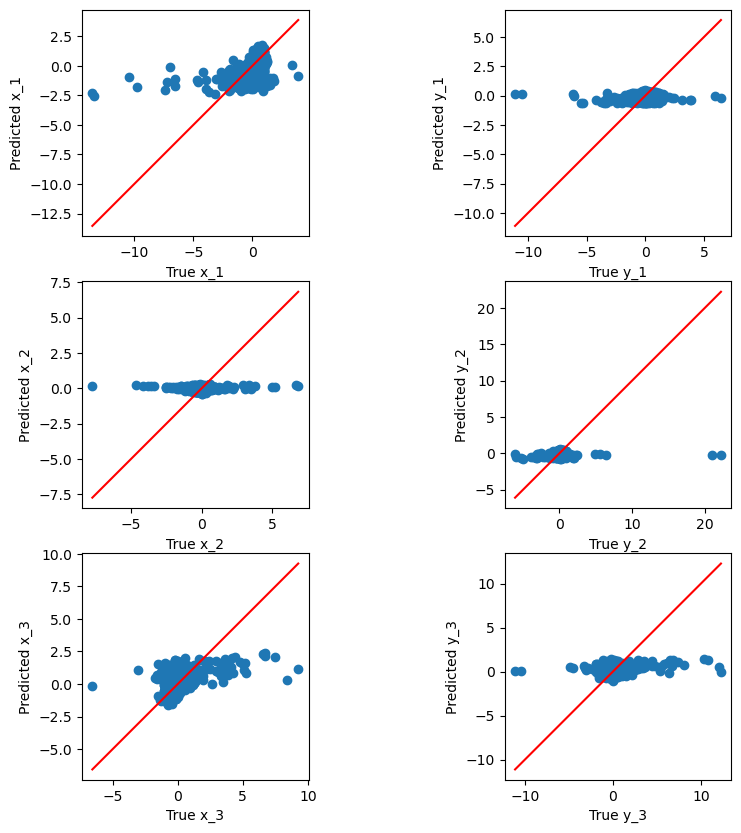

Validation RMSE: 1.3766249674147095


In [35]:
plot_y_yhat(y_dev_df.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_df, y_dev_pred)

print(f"Validation RMSE: {rmse}")

RMSE on the test set

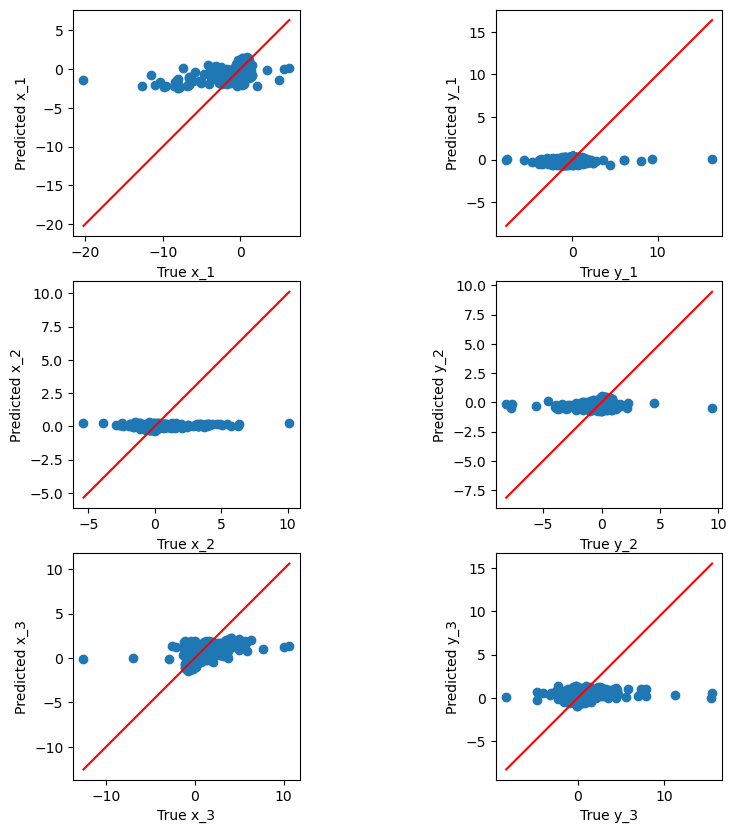

Test RMSE: 1.4524776194760773


In [36]:
y_test_pred = polyreg.predict(X_test_df)

plot_y_yhat(y_test_df.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_df, y_test_pred)

print(f"Test RMSE: {rmse}")

Dataframe containing X_tests' info for submissions. Function to save model output into csv file ready for submission

In [48]:
X_kaggle_df = pd.read_csv('../mlNOVA/X_test.csv')
X_kaggle_df.drop(columns=['Id'], inplace=True)

In [49]:
def save_predictions(predictions, path):
    df = pd.DataFrame(predictions, columns=['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])
    
    df_positions = df[['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    
    df_positions['Id'] = df_positions.index
    
    df_positions = df_positions[['Id', 'x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    
    df_positions.to_csv(path, index=False)

Regarding the baseline model for submission of task 1.2

In [46]:
y_baseline_pred = polyreg.predict(X_kaggle_df)

save_predictions(y_baseline_pred, '../submissions/baseline_model.csv')

# Task 2: Nonlinear models on the data — the Polynomial model

## Task 2.1 Development

In [50]:
def validate_poly_regression(X_train, y_train, X_val, y_val, regressor=None, degrees=range(1, 9), max_features=None):
    best_rmse = np.inf
    best_model = None
    best_degree = None

    for degree in degrees:
        
        poly = PolynomialFeatures(degree, include_bias=False)
        
        # Default to Linear Regression if no regressor is specified
        if regressor is None:
            polyreg = make_pipeline(StandardScaler(), poly, LinearRegression())
        else:
            polyreg = make_pipeline(StandardScaler(), poly, regressor)
            
        polyreg.fit(X_train, y_train)
        
        n_features = poly.n_output_features_
        
        # Abort if number of features exceeds the limit
        if max_features is not None and n_features > max_features:
            break
            
        y_pred = polyreg.predict(X_val)
        
        rmse = root_mean_squared_error(y_val, y_pred)
        
        print(f"Degree {degree}: {n_features} features | RMSE: {rmse}")
        
        if rmse < best_rmse:
            best_rmse = rmse
            best_model = polyreg
            best_degree = degree
            
    print(f"Best Degree: {best_degree}, RMSE: {best_rmse}")
    
    return best_model, best_degree, best_rmse


In [ ]:
model, degree, rmse = validate_poly_regression(X_train_df, y_train_df, X_dev_df, y_dev_df, degrees=range(1, 6), regressor=MultiTaskLassoCV())

Degree 1: 7 features | RMSE: 1.37661951042865
Degree 2: 35 features | RMSE: 1.3514229413191245


Track degrees and RMSEs over multiple runs

Degree 1: 7 features | RMSE: 1.378557139877941
Degree 2: 35 features | RMSE: 1.3581064278009756
Degree 3: 119 features | RMSE: 1.3319776241525019
Degree 4: 329 features | RMSE: 1.3378447027675522
Degree 5: 791 features | RMSE: 1.4159826754842844
Degree 6: 1715 features | RMSE: 1.3405481474829557
Degree 7: 3431 features | RMSE: 1.4031668842027927
Degree 8: 6434 features | RMSE: 1.2912258812255304
Best Degree: 8, RMSE: 1.2912258812255304
Degree 1: 7 features | RMSE: 1.3774249583414881
Degree 2: 35 features | RMSE: 1.3544634374049174
Degree 3: 119 features | RMSE: 1.3237045566287895
Degree 4: 329 features | RMSE: 1.3244611714602053
Degree 5: 791 features | RMSE: 1.4128820547568053
Degree 6: 1715 features | RMSE: 1.3197566822765106
Degree 7: 3431 features | RMSE: 1.5420611354952982
Degree 8: 6434 features | RMSE: 1.5639518740406464
Best Degree: 6, RMSE: 1.3197566822765106
Degree 1: 7 features | RMSE: 1.3768616773637496
Degree 2: 35 features | RMSE: 1.3520296427850764
Degree 3: 119 features

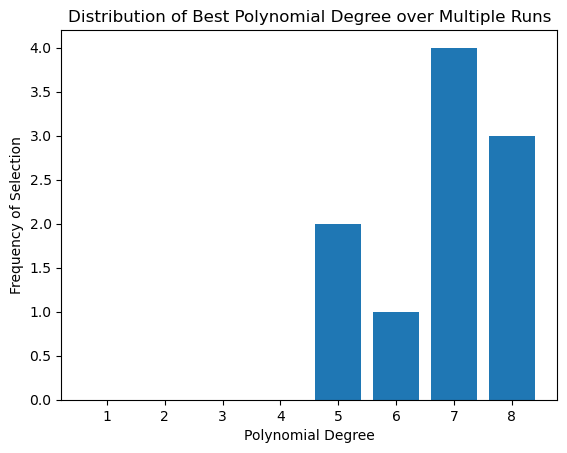

In [45]:
degree_counts = {degree: 0 for degree in range(1, 9)}

for run in range(10):
    X_train_sample, y_train_sample = resample(X_train_df, y_train_df, n_samples=int(0.01 * len(X_train_df)))
    model, degree, rmse = validate_poly_regression(X_train_sample, y_train_sample, X_dev_df, y_dev_df, degrees=range(1, 9))
    
    degree_counts[degree] += 1
  
plt.bar(degree_counts.keys(), degree_counts.values())
plt.xlabel('Polynomial Degree')
plt.ylabel('Frequency of Selection')
plt.title('Distribution of Best Polynomial Degree over Multiple Runs')
plt.show()

Degree 1: 7 features | RMSE: 1.3774902194255192
Degree 2: 35 features | RMSE: 1.3523301999079875
Degree 3: 119 features | RMSE: 1.3145768990463087
Degree 4: 329 features | RMSE: 1.2800654395856654
Degree 5: 791 features | RMSE: 1.2634528712269226
Degree 6: 1715 features | RMSE: 1.2417129494994643
Degree 7: 3431 features | RMSE: 1.2240821424980999
Degree 8: 6434 features | RMSE: 1.2187381125891656
Best Degree: 8, RMSE: 1.2187381125891656
Degree 1: 7 features | RMSE: 1.3764072539796723
Degree 2: 35 features | RMSE: 1.3517299704937706
Degree 3: 119 features | RMSE: 1.3140473032710935
Degree 4: 329 features | RMSE: 1.2812897019429113
Degree 5: 791 features | RMSE: 1.2660766770857295
Degree 6: 1715 features | RMSE: 1.2466050229359356
Degree 7: 3431 features | RMSE: 1.2274192448791788
Degree 8: 6434 features | RMSE: 1.218382368983165
Best Degree: 8, RMSE: 1.218382368983165
Degree 1: 7 features | RMSE: 1.3769549421282745
Degree 2: 35 features | RMSE: 1.3525662891466717
Degree 3: 119 features 

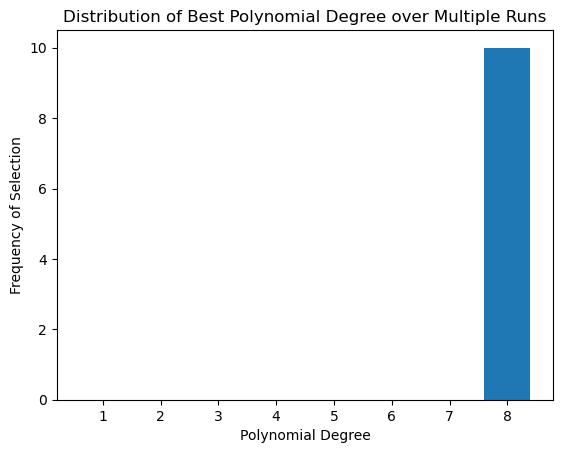

In [46]:
degree_counts = {degree: 0 for degree in range(1,9)}

for run in range(10):
    X_train_sample, y_train_sample = resample(X_train_df, y_train_df, n_samples=int(0.01 * len(X_train_df)))
    model, degree, rmse = validate_poly_regression(X_train_sample, y_train_sample, X_dev_df, y_dev_df, regressor = RidgeCV(), degrees=range(1, 9))
    
    # Track the best degree for this run
    degree_counts[degree] += 1
  
plt.bar(degree_counts.keys(), degree_counts.values())
plt.xlabel('Polynomial Degree')
plt.ylabel('Frequency of Selection')
plt.title('Distribution of Best Polynomial Degree over Multiple Runs')
plt.show()

## Task 2.2 Evaluation

### Evaluate your new nonlinear model against your baseline. Compare RMSE and the y-y hat plots. 

8 was the best performing degree of polynomial in linear regression. But given the size of the training data used to train the model, there is not enough memory to fit it to a 8th degree polynomial regression. The best we could do is degree 7, which as shown by the histogram above, is one of the contenders for best model.

In [49]:
degree=7

polyreg = make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('polynomialfeatures',
                 PolynomialFeatures(degree=7, include_bias=False)),
                ('linearregression', LinearRegression())])

Plot y-y hat in validation set and present RMSE

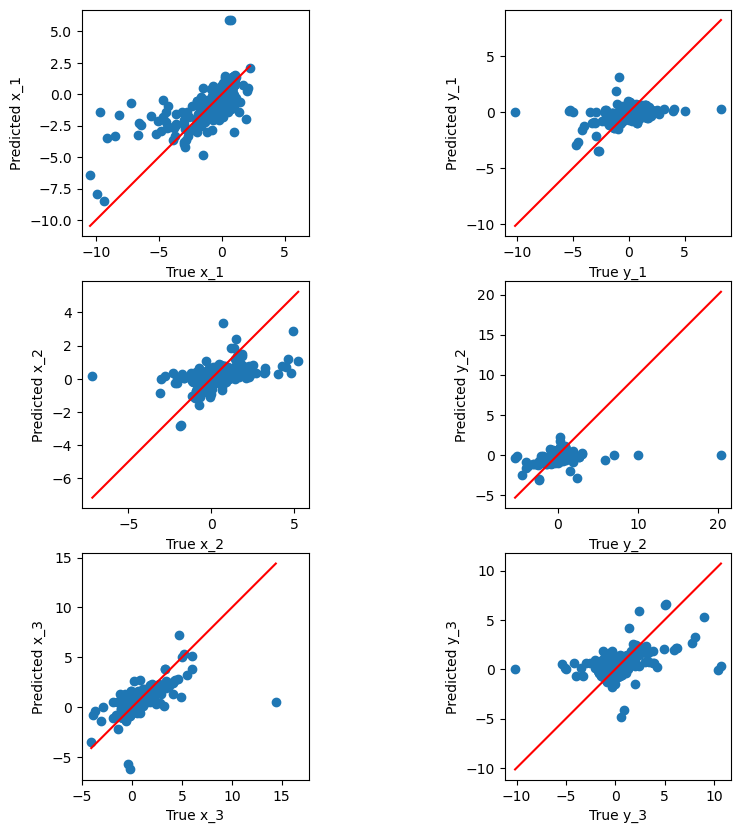

Validation RMSE: 1.2372732161464846


In [50]:
y_dev_pred = polyreg.predict(X_dev_df)

plot_y_yhat(y_dev_df.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_df, y_dev_pred)

print(f"Validation RMSE: {rmse}")

RMSE in the test set

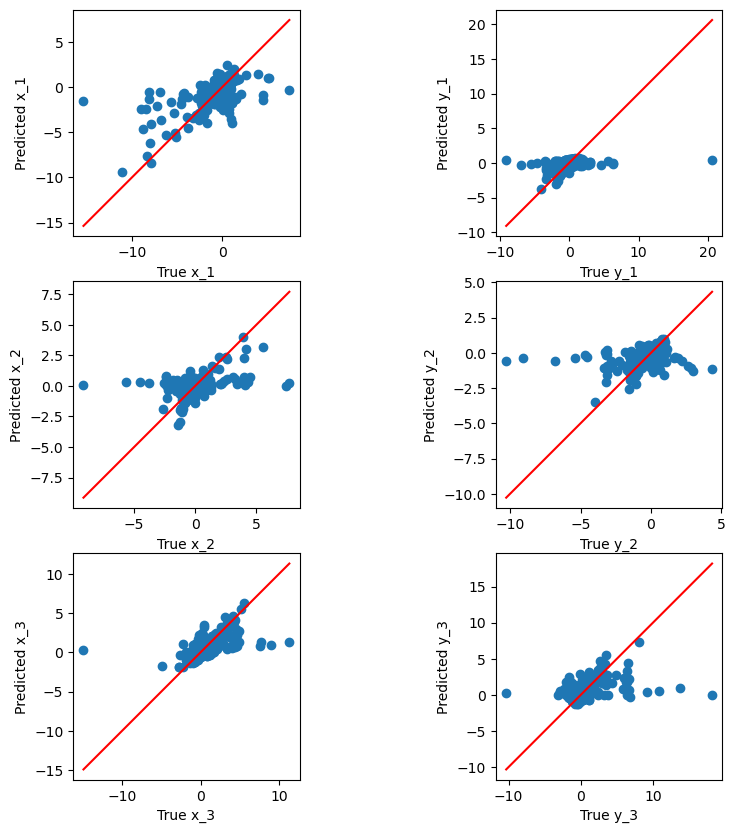

Test RMSE: 1.2758654959318019


In [52]:
y_test_pred = polyreg.predict(X_test_df)

plot_y_yhat(y_test_df.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_df, y_test_pred)

print(f"Test RMSE: {rmse}")

Regarding the polynomial model for submission of task 2.2

In [74]:
y_polynomial_pred = polyreg.predict(X_kaggle_df)

save_predictions(y_polynomial_pred, '../submissions/polynomial_submission.csv')

Try out RidgeCV and the best degree was 8

In [71]:
degree = 6

polyreg=make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      RidgeCV())

# Fit the model
polyreg.fit(X_train_df, y_train_df)

# Predict the targets for the validation set
y_dev_pred = polyreg.predict(X_dev_df)

In [75]:
print(type(polyreg))
initial_type = [('float_input', FloatTensorType([None, X_kaggle_df.shape[1]]))]  

# Convert the model to ONNX format
onnx_model = convert_sklearn(polyreg, initial_types=initial_type)

# Save the ONNX model to a file
with open("baseline-model.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())

<class 'sklearn.pipeline.Pipeline'>


RMSE in validation set for RidgeCV

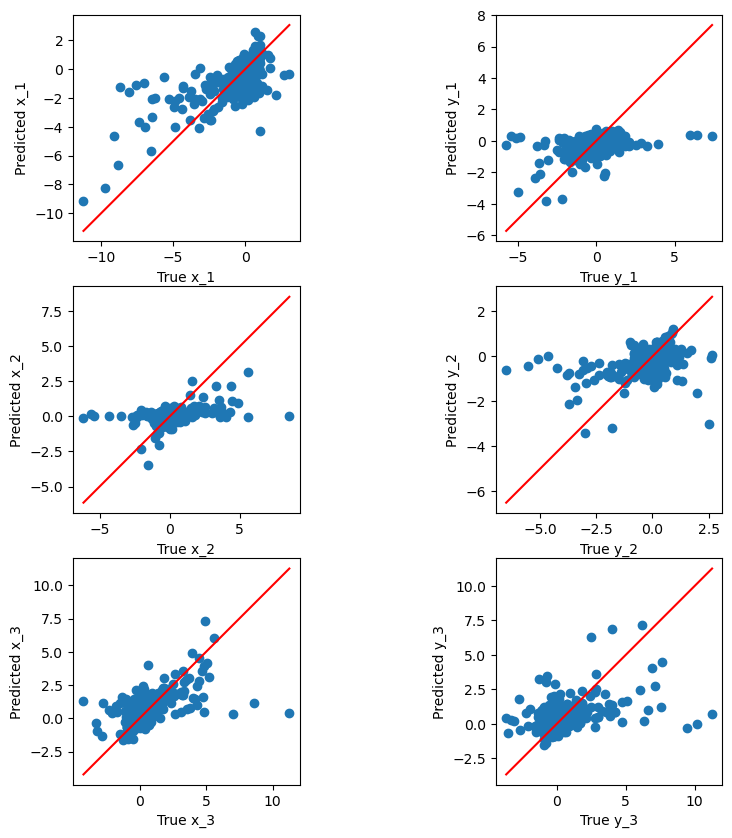

Validation RMSE: 1.2394613366013878


In [72]:
y_dev_pred = polyreg.predict(X_dev_df)

plot_y_yhat(y_dev_df.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_df, y_dev_pred)

print(f"Validation RMSE: {rmse}")

RMSE in test set for RidgeCV

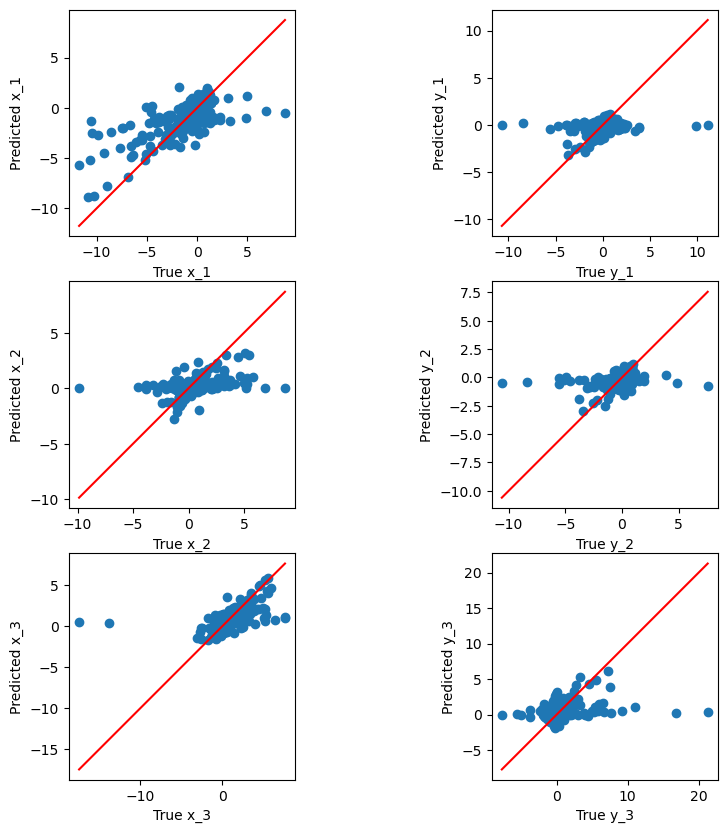

Test RMSE: 1.2953546394428888


In [73]:
y_test_pred = polyreg.predict(X_test_df)

plot_y_yhat(y_test_df.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_df, y_test_pred)

print(f"Test RMSE: {rmse}")

# Task 3: Feature Engineering

## Task 3.1 Removing variables

Explore the features and verify if there are any linear relationships between them. 

Remember, features should be uncorrelated with each other and highly correlated with the target variables. Use the Seaborn package to inspect these relationships.

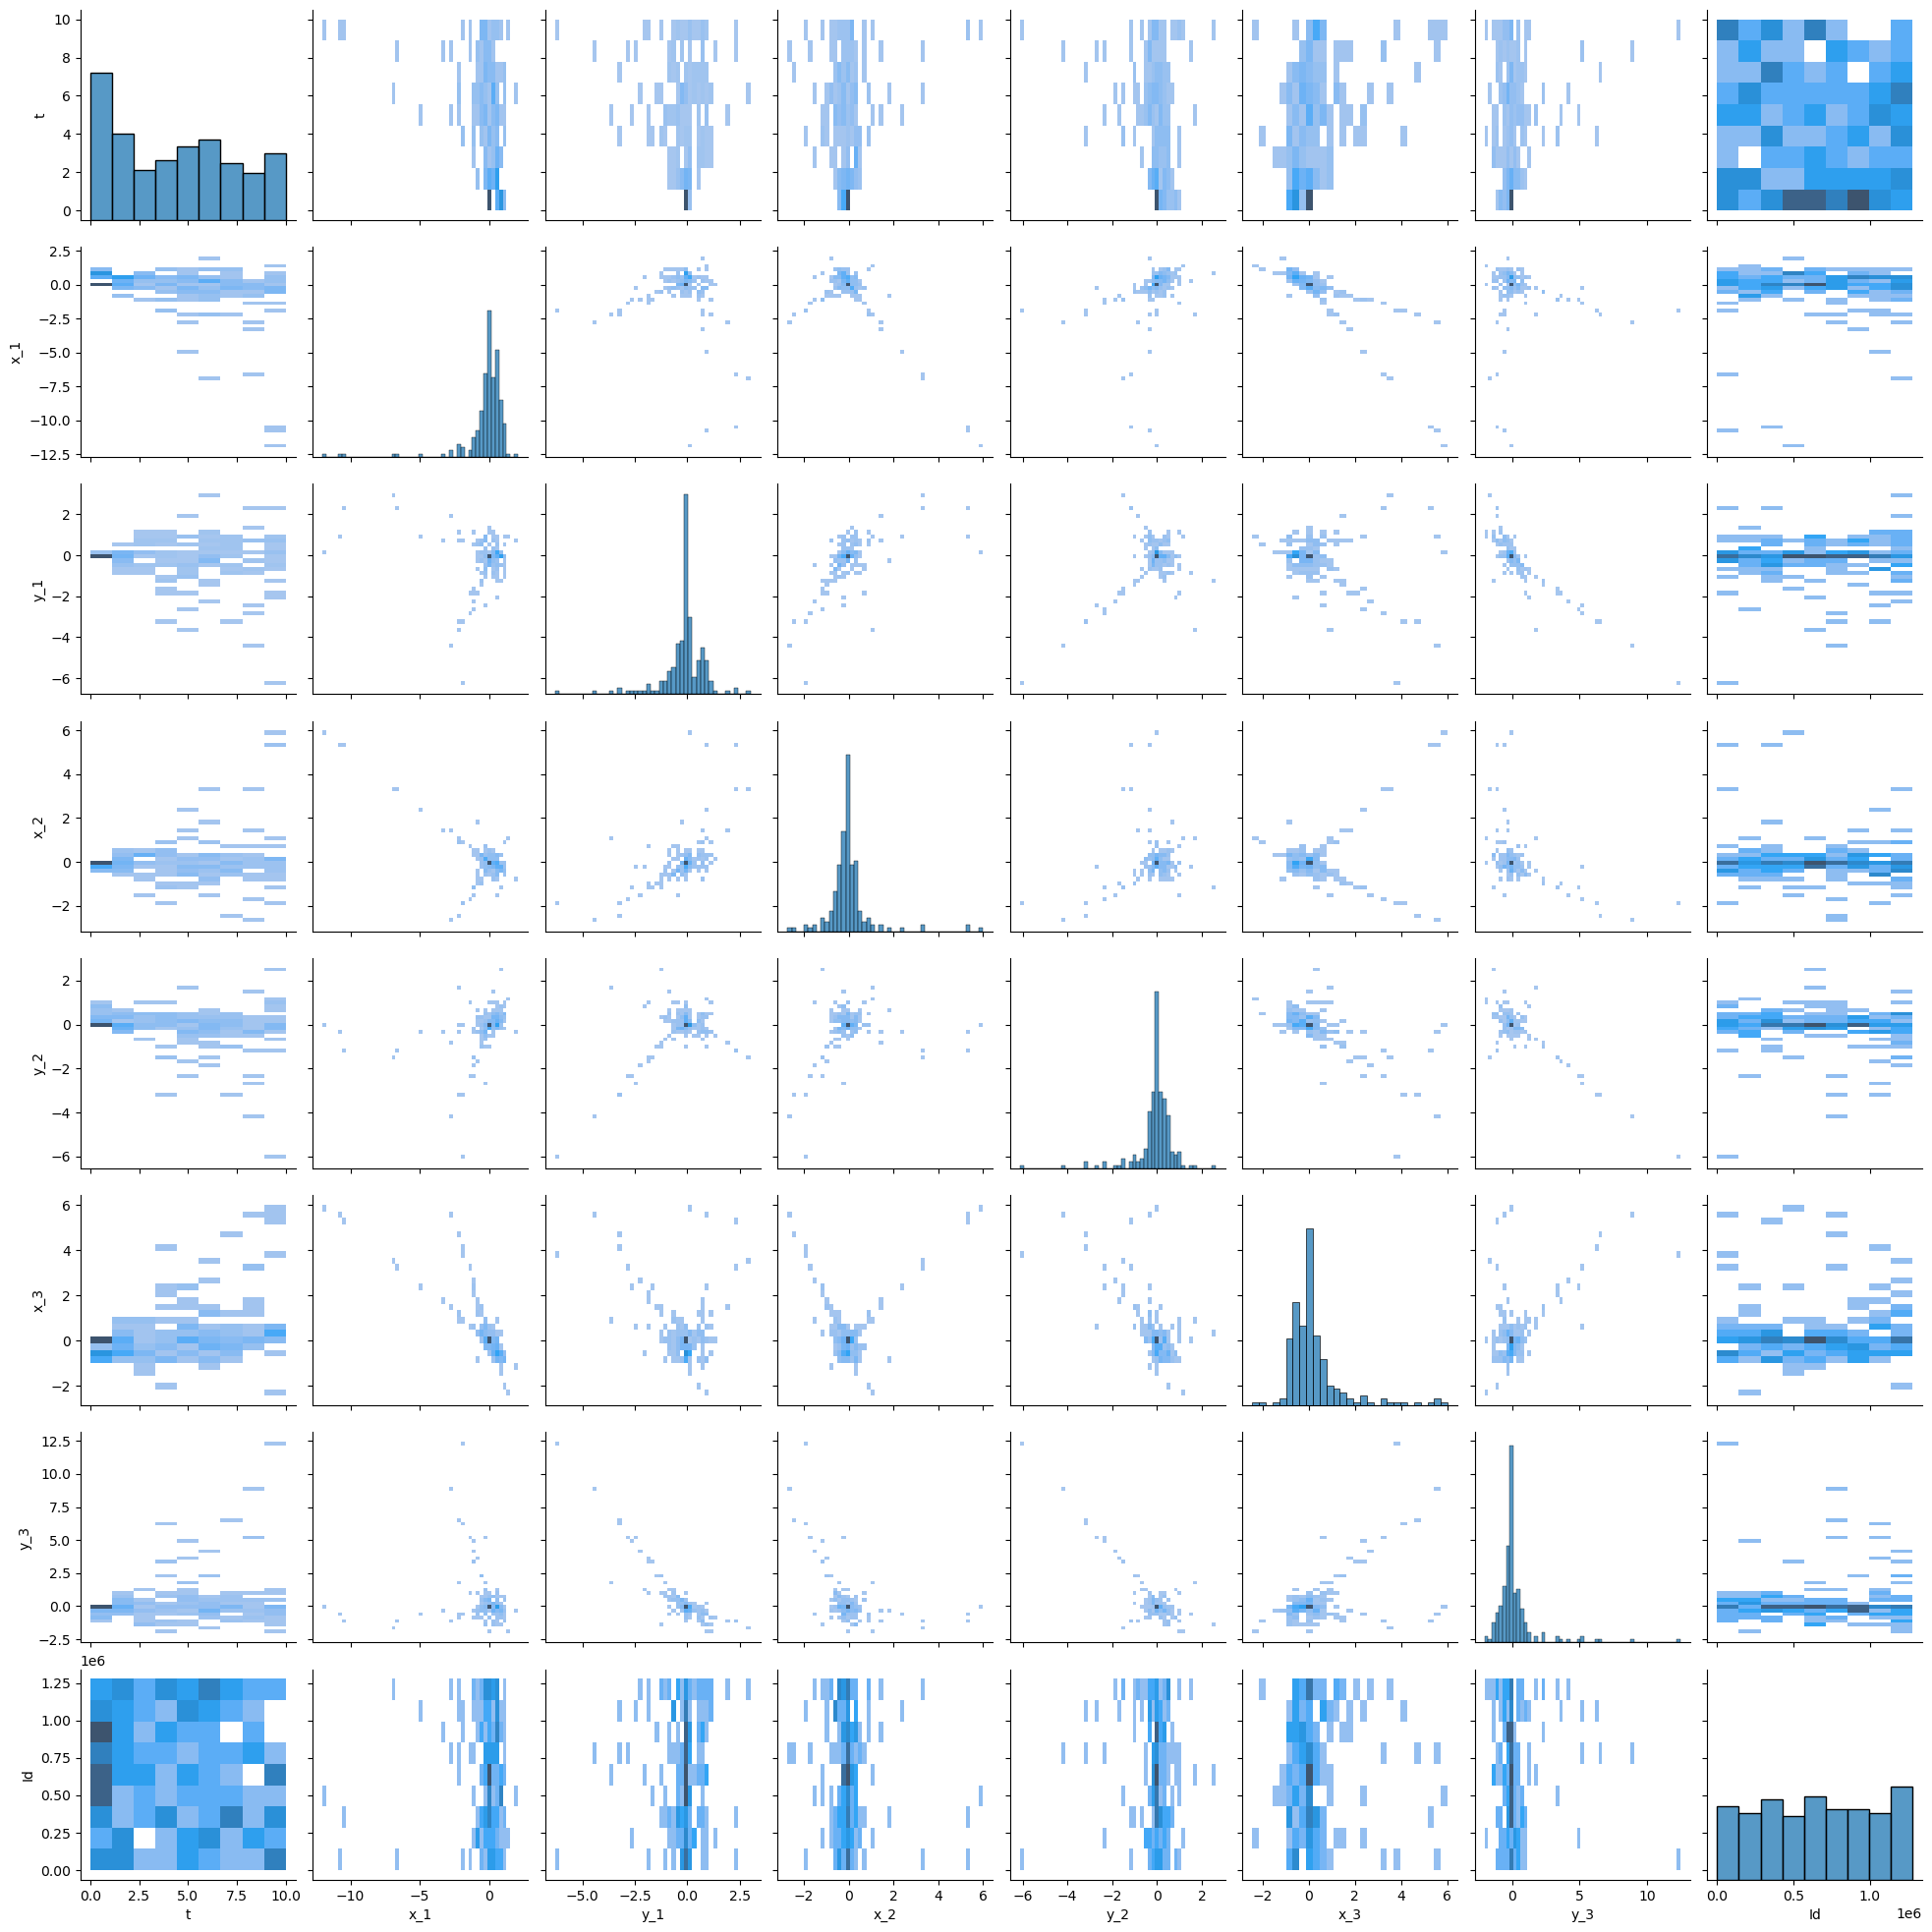

In [61]:
sns.pairplot(df.sample(200), kind="hist")

<Axes: >

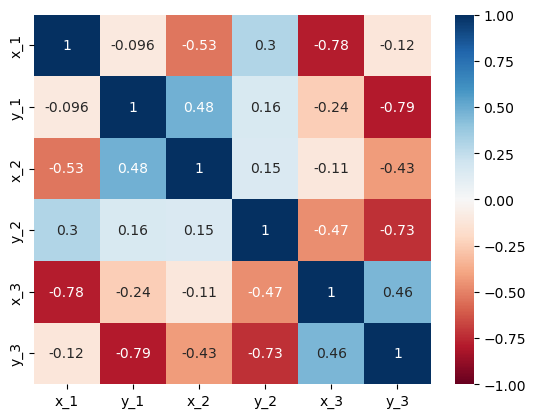

In [68]:
df_no_id_t = df.drop(columns=['t','Id'])
corr = df_no_id_t.corr()
sns.heatmap(corr, annot=True, cmap='RdBu', vmin = -1, vmax = 1)

<Axes: >

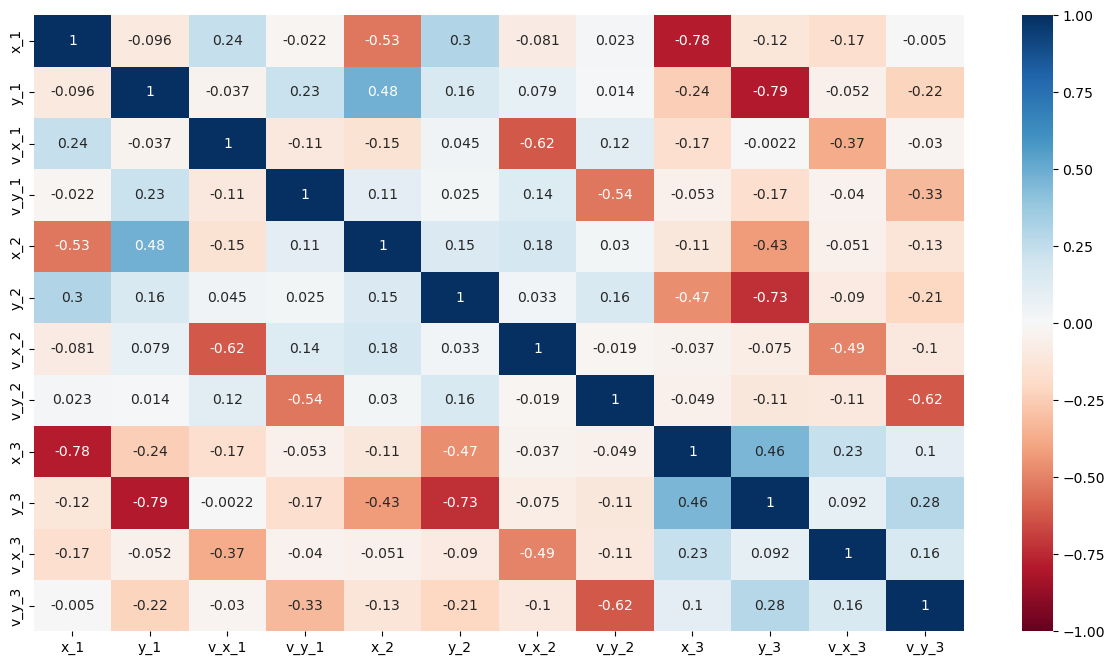

In [70]:
df_with_v = pd.read_csv('../mlNOVA/X_train.csv')
df_v_no_id_t = df_with_v.drop(columns=['t','Id'])
corr = df_v_no_id_t.corr()

plt.figure(figsize=(15,8))
sns.heatmap(corr, annot=True, cmap='RdBu', vmin = -1, vmax = 1)

### Eliminating y_3 as a feature

In [77]:
subframes = fixed_size_subframes(df, SUBFRAME_SIZE)

In [79]:
subframes = remove_useless_rows(subframes)
len(subframes)

4998

In [84]:
def create_features_and_targets(cleaned_subframes, feature_labels, target_labels):
    X_chunks = []
    y_chunks = []
    
    for df in cleaned_subframes:
        if df.empty:
            continue
        
        # Get initial conditions as numpy array
        initial_conditions = df.iloc[0][feature_labels].values
        
        # Use vectorized operations to create features
        time_values = df['t'].values
        initial_conditions_repeated = np.tile(initial_conditions, (len(df), 1))  # Repeat initial conditions for all rows
        X_chunk = np.column_stack((time_values, initial_conditions_repeated))  # Combine time with initial conditions
        
        # Convert to DataFrame
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        
        # Extract targets using vectorized operations
        y_chunk_df = df[target_labels].copy()  # Directly slice the target columns from the dataframe
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)
    
    return X_chunks, y_chunks

X_chunks, y_chunks = create_features_and_targets(subframes, ['y_1', 'x_2', 'y_2', 'x_3'], ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])

In [85]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

X_train_df = pd.concat(X_train, axis=0)
y_train_df = pd.concat(y_train, axis=0)

X_dev_df = pd.concat(X_dev, axis=0)
y_dev_df = pd.concat(y_dev, axis=0)

X_test_df = pd.concat(X_test, axis=0)
y_test_df = pd.concat(y_test, axis=0)

In [86]:
X_train[0].head()

,t,x0_1,y0_1,x0_2,y0_2,x0_3
0,0.000000,1.0,0.0,-0.264968,0.411689,-0.735032
1,0.039062,1.0,0.0,-0.264968,0.411689,-0.735032
2,0.078125,1.0,0.0,-0.264968,0.411689,-0.735032
3,0.117188,1.0,0.0,-0.264968,0.411689,-0.735032
4,0.156250,1.0,0.0,-0.264968,0.411689,-0.735032


In [87]:
polyreg=make_pipeline(StandardScaler(),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

y_dev_pred = polyreg.predict(X_dev_df)

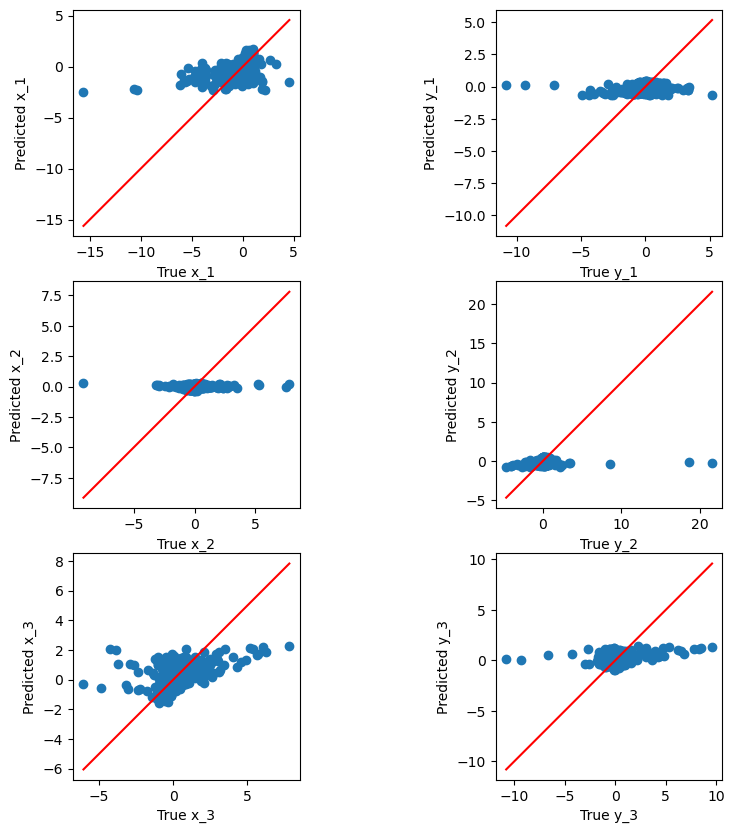

Validation RMSE: 1.376639320949387


In [88]:
plot_y_yhat(y_dev_df.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_df, y_dev_pred)

print(f"Validation RMSE: {rmse}")

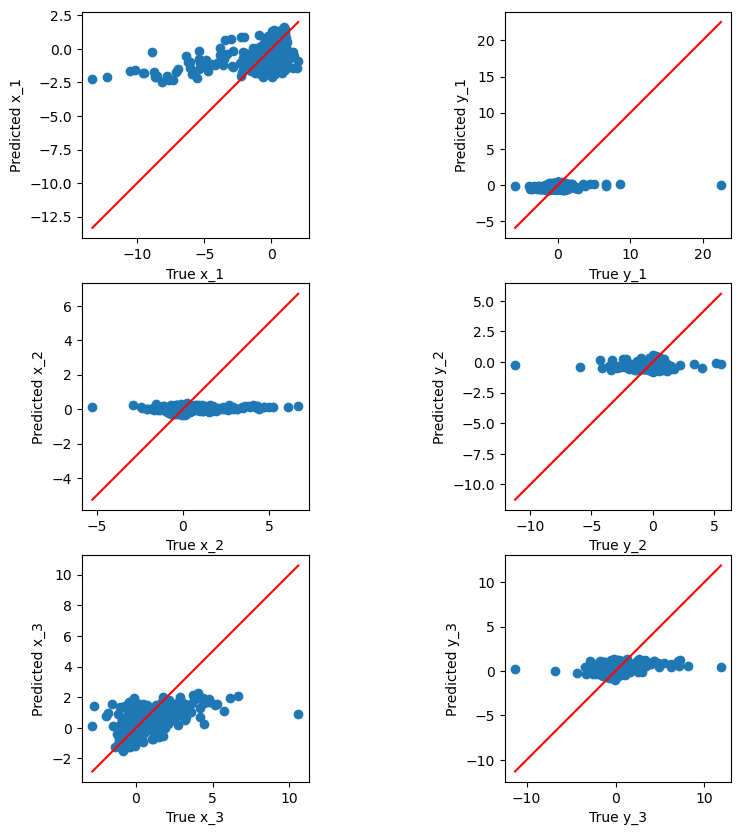

Test RMSE: 1.4524799295711415


In [89]:
y_test_pred = polyreg.predict(X_test_df)

plot_y_yhat(y_test_df.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_df, y_test_pred)

print(f"Test RMSE: {rmse}")

### Eliminating x_1 as a feature

In [91]:
def create_features_and_targets(cleaned_subframes, feature_labels, target_labels):
    X_chunks = []
    y_chunks = []
    
    for df in cleaned_subframes:
        if df.empty:
            continue
        
        # Get initial conditions as numpy array
        initial_conditions = df.iloc[0][feature_labels].values
        
        # Use vectorized operations to create features
        time_values = df['t'].values
        initial_conditions_repeated = np.tile(initial_conditions, (len(df), 1))  # Repeat initial conditions for all rows
        X_chunk = np.column_stack((time_values, initial_conditions_repeated))  # Combine time with initial conditions
        
        # Convert to DataFrame
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        
        # Extract targets using vectorized operations
        y_chunk_df = df[target_labels].copy()  # Directly slice the target columns from the dataframe
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)
    
    return X_chunks, y_chunks

X_chunks, y_chunks = create_features_and_targets(subframes, ['y_1', 'x_2', 'y_2', 'x_3'], ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])

In [93]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

X_train_df = pd.concat(X_train, axis=0)
y_train_df = pd.concat(y_train, axis=0)

X_dev_df = pd.concat(X_dev, axis=0)
y_dev_df = pd.concat(y_dev, axis=0)

X_test_df = pd.concat(X_test, axis=0)
y_test_df = pd.concat(y_test, axis=0)

In [94]:
polyreg=make_pipeline(StandardScaler(),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

y_dev_pred = polyreg.predict(X_dev_df)

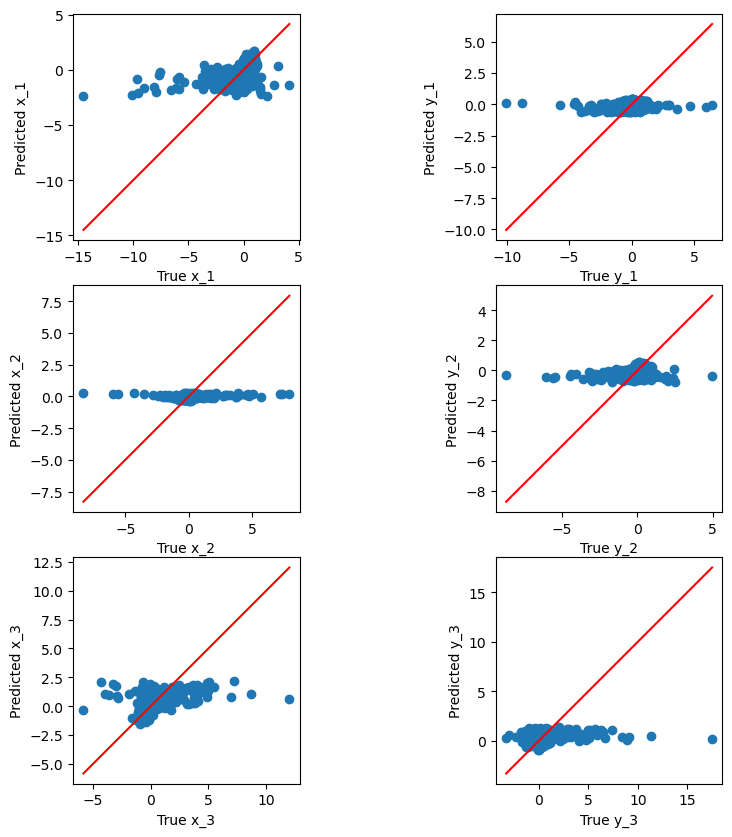

Validation RMSE: 1.3766261446822874


In [95]:
plot_y_yhat(y_dev_df.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_df, y_dev_pred)

print(f"Validation RMSE: {rmse}")

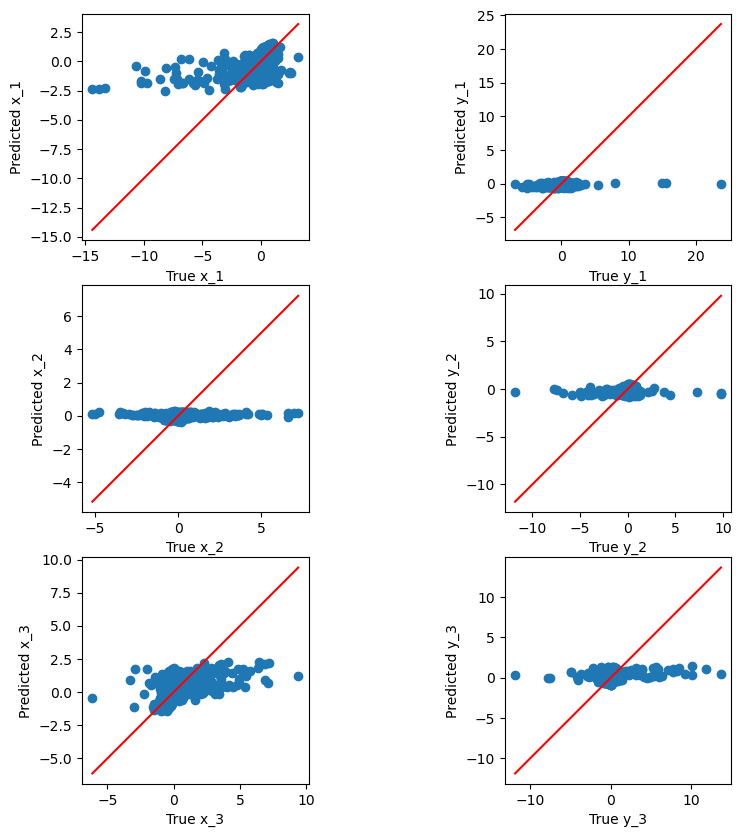

Test RMSE: 1.452475933574193


In [96]:
y_test_pred = polyreg.predict(X_test_df)

plot_y_yhat(y_test_df.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_df, y_test_pred)

print(f"Test RMSE: {rmse}")